# 06. Graph Community Detection & Echo Chamber Analysis

- **Role/Owner:** Member 3 (Analytics, Graph & Visualization Lead)
- **Core Responsibility:** Group PHEME rumour cascades into communities with two different methods (K-Means and Louvain), and study whether misinformation concentrates in some of them.
- **Key Interface/Contract:** Consumes `backend/data/pheme_political/pheme_cascades.gpickle` and `backend/data/processed/cascade_features.csv`; outputs `backend/models/community_clusters.joblib`, `backend/data/processed/network_sample.json` (for `GET /api/cascades/network`) and `backend/reports/community_metrics.json`.

**Important design decision: communities of cascades, not of users.**
The original plan was a user-user graph. The graph file does not allow that: every node is a tweet, there is no user id or handle, and no tweet appears in more than one cascade (checked in Section 2). Each cascade is therefore a separate tree and users cannot be linked across cascades. Instead, each **cascade** becomes one point, described by the text embedding of its source tweet. Cascades that retell the same story end up close together. We call the groups **narrative communities**. This still uses both required methods (K-Means on the vectors, Louvain on a similarity graph), but it answers a slightly different question than "which users form an echo chamber". Section 11 asks you to explain what the results can and cannot say.

**What this notebook does**

1. Load the source-tweet embedding of each of the 6,425 cascades and attach event, veracity and author data.
2. K-Means on the embeddings (number of clusters chosen with the silhouette score).
3. Build a nearest-neighbour similarity graph and run Louvain (community detection by modularity).
4. Compare the two methods and check how much they just recover the news event.
5. Profile each community: share of false rumours, author followers, verified share, cascade size.
6. Test with statistics whether false rumours concentrate in some communities.
7. Export the clustering, a 300-node sample for the D3 network graph, and a metrics report.

## 1. Setup

In [17]:
from pathlib import Path
import json
import pickle
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import joblib
import sklearn
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
KNN = 10               # each cascade is linked to its 10 most similar cascades
RESOLUTION = 1.0       # Louvain default resolution
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
GRAPH_FILE = ROOT / "backend" / "data" / "pheme_political" / "pheme_cascades.gpickle"
CSV_FILE = ROOT / "backend" / "data" / "processed" / "cascade_features.csv"
MODELS = ROOT / "backend" / "models"
REPORTS = ROOT / "backend" / "reports"
PROCESSED = ROOT / "backend" / "data" / "processed"
MODELS.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
print("repo root:", ROOT)

repo root: c:\Users\Admin\Documents\COS30049-political-misinfo


## 2. Load the embedding of each cascade's source tweet

`pheme_cascades.gpickle` is a list of 6,425 NetworkX graphs, one per cascade. Every node is a tweet with attributes such as `text`, `user_followers`, `user_verified` and `text_embedding` (a 384-number vector, already scaled to length 1). The source tweet of a cascade is the node whose id equals the graph's `thread_id`. We do **not** use the `is_source` flag, because it is `False` for some source tweets.

While loading, we also count how many tweet ids appear in more than one cascade. If the count is 0, cascades cannot be joined through shared tweets, which is the evidence for the design decision above. Loading the 184 MB file takes about 40 seconds.

In [18]:
def load_root_embeddings(path):
    with open(path, "rb") as f:               # nx.read_gpickle no longer exists, so use pickle directly
        graphs = pickle.load(f)
    ids, embs, counter = [], [], Counter()
    for g in graphs:
        tid = str(g.graph["thread_id"])
        root = g.nodes[tid]
        ids.append(tid)
        embs.append(np.asarray(root["text_embedding"], dtype=np.float32))
        counter.update(list(g))
    n_tweets = len(counter)
    n_shared = sum(1 for c in counter.values() if c > 1)
    return np.array(ids), np.vstack(embs), n_tweets, n_shared


ids, E, n_tweets, n_shared = load_root_embeddings(GRAPH_FILE)
E = E / np.linalg.norm(E, axis=1, keepdims=True)    # make sure every vector has length 1
print("embeddings:", E.shape, "| distinct cascades:", len(set(ids)))
print(f"tweets in total: {n_tweets:,} | tweets that appear in more than one cascade: {n_shared}")

embeddings: (6425, 384) | distinct cascades: 6425
tweets in total: 105,747 | tweets that appear in more than one cascade: 0


## 3. Attach event, veracity and author data

The embeddings are matched to `cascade_features.csv` through the cascade id. Clustering itself does not use any label (it is unsupervised). Labels are only used afterwards to describe the communities.

- `mis = 1` for rumours annotated **false**, `mis = 0` for **true** rumours and **non-rumours**, and `mis = NaN` for **unverified** rumours (their truth is unknown, so they are left out of every rate below).
- `prince-toronto` and `ebola-essien` are almost entirely false (98%), so the event alone would decide the label. The team already dropped them from the text models. We keep them in the clustering but report the main results **without** them (`main_event = True`), otherwise the finding "false rumours concentrate somewhere" would be trivial.

In [19]:
feat = pd.read_csv(CSV_FILE)
feat["cascade_id"] = feat["cascade_id"].astype(str)
meta = pd.DataFrame({"cascade_id": ids}).merge(feat, on="cascade_id", how="left", validate="one_to_one")
assert len(meta) == len(E) == 6425 and meta["event"].notna().all()

meta["event_short"] = meta["event"].str.replace("-all-rnr-threads", "", regex=False)
meta["mis"] = meta["veracity"].map({"false": 1.0, "true": 0.0, "non-rumour": 0.0})
meta["main_event"] = ~meta["event"].str.contains("prince|ebola")

print(pd.crosstab(meta["event_short"], meta["veracity"]))
print()
print("false-rumour share, main events, known veracity:",
      round(meta.loc[meta["main_event"], "mis"].mean(), 3))

veracity           false  non-rumour  true  unverified
event_short                                           
charliehebdo         116        1621   193         149
ebola-essien          14           0     0           0
ferguson               8         859    10         266
germanwings-crash    111         231    94          33
gurlitt                0          77    59           2
ottawashooting        72         420   329          69
prince-toronto       222           4     0           7
putinmissing           9         112     0         117
sydneysiege           86         699   382          54

false-rumour share, main events, known veracity: 0.073


## 4. Method 1: K-Means on the embeddings

K-Means needs the number of clusters `k` in advance. We try `k` from 3 to 12 and keep the value with the best **silhouette score** (how well each point fits its own cluster compared with the nearest other cluster; higher is better, 1 is perfect). The silhouette is computed on a random sample of 3,000 points to keep it fast. Text embeddings are high-dimensional, so scores are expected to be low in absolute terms. What matters is the comparison between different `k`.

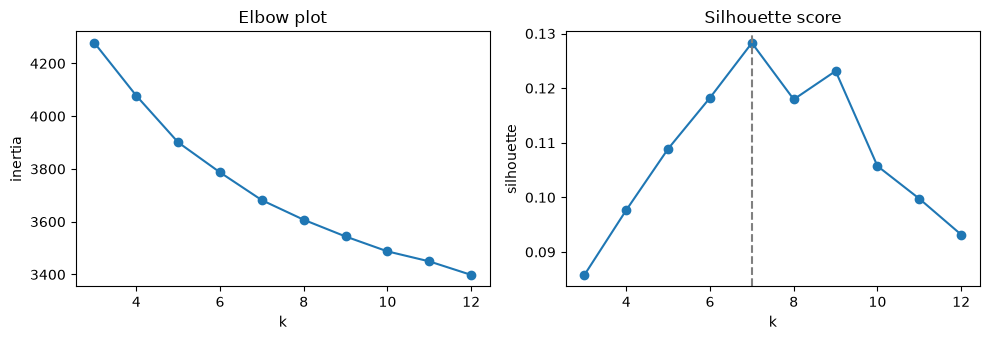

chosen k: 7


,k,inertia,silhouette
0,3,4277.5864,0.0858
1,4,4077.5498,0.0977
2,5,3900.6328,0.1089
3,6,3786.9204,0.1182
4,7,3681.5664,0.1283
5,8,3607.3188,0.1179
6,9,3543.9805,0.1231
7,10,3487.5879,0.1057
8,11,3449.6528,0.0998
9,12,3398.4148,0.0932


In [20]:
rows = []
for k in range(3, 13):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(E)
    rows.append({"k": k, "inertia": float(km_k.inertia_),
                 "silhouette": float(silhouette_score(E, km_k.labels_, sample_size=3000, random_state=SEED))})
k_table = pd.DataFrame(rows)
best_k = int(k_table.sort_values("silhouette", ascending=False).iloc[0]["k"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(k_table["k"], k_table["inertia"], marker="o")
ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia"); ax[0].set_title("Elbow plot")
ax[1].plot(k_table["k"], k_table["silhouette"], marker="o")
ax[1].axvline(best_k, linestyle="--", color="gray")
ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette"); ax[1].set_title("Silhouette score")
plt.tight_layout(); plt.show()

km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(E)
meta["kmeans"] = km.labels_
print("chosen k:", best_k)
k_table.round(4)

## 5. Method 2: Louvain on a similarity graph

Louvain finds communities in a graph by maximising **modularity** (how much more strongly nodes are connected inside their community than expected by chance; values above about 0.3 are usually read as real community structure). It needs a graph, so we build one: every cascade is linked to its 10 nearest cascades by cosine similarity, and the similarity is the edge weight. Louvain has a `resolution` setting: low values give few large communities, high values give many small ones. The table below shows the effect, and the standard value 1.0 is used for the main analysis (it was not tuned to get a nice result).

In [21]:
def knn_graph(E, k=KNN):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(E)
    dist, idx = nn.kneighbors(E)
    G = nx.Graph()
    G.add_nodes_from(range(len(E)))
    for i in range(len(E)):
        for d, j in zip(dist[i, 1:], idx[i, 1:]):
            j = int(j)
            if j == i:
                continue
            w = max(1.0 - float(d), 0.0)
            if G.has_edge(i, j):
                G[i][j]["weight"] = max(G[i][j]["weight"], w)
            else:
                G.add_edge(i, j, weight=w)
    return G


def louvain_labels(G, resolution):
    comms = sorted(nx.community.louvain_communities(G, weight="weight", resolution=resolution, seed=SEED),
                   key=len, reverse=True)                      # community 0 = the largest
    lab = np.zeros(G.number_of_nodes(), dtype=int)
    for c, nodes in enumerate(comms):
        for n in nodes:
            lab[n] = c
    q = nx.community.modularity(G, comms, weight="weight", resolution=resolution)
    return lab, float(q), len(comms)


t0 = time.time()
G = knn_graph(E)
print(f"graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges ({time.time() - t0:.1f}s)")

rows = []
for res in [0.3, 0.5, 0.8, 1.0, 1.5, 2.0]:
    lab, q, n = louvain_labels(G, res)
    rows.append({"resolution": res, "communities": n, "modularity": q,
                 "ARI vs event": adjusted_rand_score(meta["event"], lab)})
res_table = pd.DataFrame(rows).round(3)
res_table

graph: 6,425 nodes, 51,033 edges (1.3s)


,resolution,communities,modularity,ARI vs event
0,0.3,12,0.934,0.909
1,0.5,15,0.900,0.846
2,0.8,19,0.863,0.612
3,1.0,23,0.843,0.533
4,1.5,30,0.806,0.389
5,2.0,34,0.777,0.336


In [22]:
lab, Q, n_comm = louvain_labels(G, RESOLUTION)
meta["louvain"] = lab
print(f"Louvain (resolution {RESOLUTION}): {n_comm} communities, modularity Q = {Q:.3f}")
print("largest communities:", meta["louvain"].value_counts().head(8).to_dict())

Louvain (resolution 1.0): 23 communities, modularity Q = 0.843
largest communities: {0: 1135, 1: 682, 2: 681, 3: 553, 4: 528, 5: 400, 6: 376, 7: 363}


## 6. How do the two methods compare, and do they just recover the news event?

- **ARI** (adjusted Rand index) and **NMI** (normalised mutual information) measure how similar two groupings are. 1 means identical, 0 means no more similar than random.
- If a clustering has a high ARI with `event`, it mostly rediscovered which news story a tweet is about.

In [23]:
pairs = {
    "K-Means vs Louvain": (meta["kmeans"], meta["louvain"]),
    "K-Means vs event": (meta["kmeans"], meta["event"]),
    "Louvain vs event": (meta["louvain"], meta["event"]),
}
compare = pd.DataFrame({name: {"ARI": adjusted_rand_score(a, b), "NMI": normalized_mutual_info_score(a, b)}
                        for name, (a, b) in pairs.items()}).T.round(3)
compare

,ARI,NMI
K-Means vs Louvain,0.556,0.720
K-Means vs event,0.790,0.857
Louvain vs event,0.533,0.777


### Map of the cascades

t-SNE squeezes the 384 numbers into 2 so that similar cascades land near each other. The left plot is coloured by Louvain community (only the 8 largest are named), the right plot by veracity. The shape of the map is only a visual aid and should not be read as exact distances.

t-SNE done in 49s


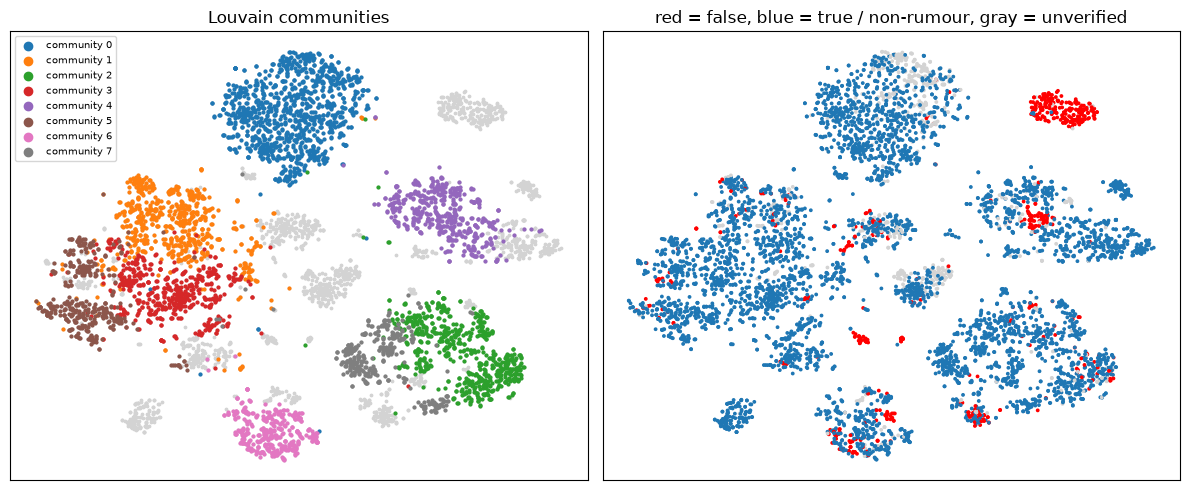

In [24]:
t0 = time.time()
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(PCA(n_components=50, random_state=SEED).fit_transform(E))
print(f"t-SNE done in {time.time() - t0:.0f}s")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
top = meta["louvain"].value_counts().index[:8]
ax[0].scatter(xy[:, 0], xy[:, 1], s=3, c="lightgray")
for c in top:
    m_ = (meta["louvain"] == c).to_numpy()
    ax[0].scatter(xy[m_, 0], xy[m_, 1], s=4, label=f"community {c}")
ax[0].legend(markerscale=3, fontsize=7); ax[0].set_title("Louvain communities")
colors = meta["mis"].map({1.0: "red", 0.0: "tab:blue"}).fillna("lightgray")
ax[1].scatter(xy[:, 0], xy[:, 1], s=3, c=colors)
ax[1].set_title("red = false, blue = true / non-rumour, gray = unverified")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 7. Profile of each narrative community

Only cascades from the main events with a known veracity are used here. `event_purity` is the share of the community that comes from its most common event. A table of the Louvain communities with at least 30 cascades is shown, then the K-Means clusters.

In [25]:
known = meta[meta["main_event"] & meta["mis"].notna()].copy()


def profile(d, col):
    g = d.groupby(col)
    return pd.DataFrame({
        "cascades": g.size(),
        "false_rate": g["mis"].mean(),
        "top_event": g["event_short"].agg(lambda s: s.value_counts().index[0]),
        "event_purity": g["event_short"].agg(lambda s: s.value_counts(normalize=True).iloc[0]),
        "median_followers": g["root_user_followers"].median(),
        "verified_share": g["root_user_verified"].mean(),
        "mean_size": g["cascade_size"].mean(),
    }).round(3)


louvain_profile = profile(known, "louvain")
louvain_shown = louvain_profile[louvain_profile["cascades"] >= 30]
print("Louvain communities with >= 30 cascades:", len(louvain_shown), "of", len(louvain_profile))
louvain_shown

Louvain communities with >= 30 cascades: 17 of 22


,cascades,false_rate,top_event,event_purity,median_followers,verified_share,mean_size
louvain,,,,,,,
0,868,0.010,ferguson,0.982,25766.0,0.380,20.507
1,618,0.073,charliehebdo,0.995,679757.0,0.710,16.061
2,637,0.074,sydneysiege,0.997,170463.0,0.725,17.104
3,532,0.026,charliehebdo,0.994,31471.0,0.342,25.703
4,466,0.150,ottawashooting,1.000,167385.5,0.727,13.946
5,390,0.033,charliehebdo,1.000,28754.5,0.446,18.062
6,355,0.208,germanwings-crash,0.994,258612.0,0.693,8.183
7,361,0.011,sydneysiege,0.983,32894.0,0.410,23.022
8,126,0.071,putinmissing,0.952,946.0,0.048,3.698


In [26]:
kmeans_profile = profile(known, "kmeans")
kmeans_profile

,cascades,false_rate,top_event,event_purity,median_followers,verified_share,mean_size
kmeans,,,,,,,
0,825,0.078,charliehebdo,0.607,19863.0,0.398,12.314
1,1421,0.050,charliehebdo,0.999,59590.0,0.522,19.467
3,1151,0.075,sydneysiege,0.997,122267.0,0.620,19.876
4,888,0.009,ferguson,0.975,25787.5,0.380,20.383
5,788,0.091,ottawashooting,0.987,107944.5,0.689,13.703
6,415,0.243,germanwings-crash,0.998,214179.0,0.651,9.041


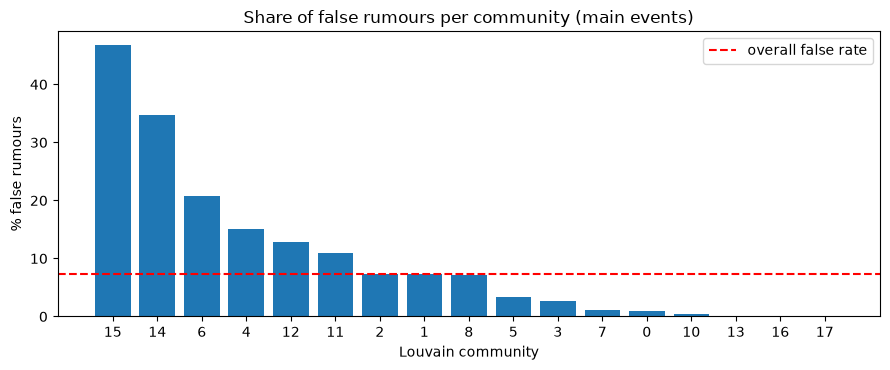

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = louvain_shown.sort_values("false_rate", ascending=False)
ax.bar(order.index.astype(str), order["false_rate"] * 100)
ax.axhline(known["mis"].mean() * 100, color="red", linestyle="--", label="overall false rate")
ax.set_xlabel("Louvain community"); ax.set_ylabel("% false rumours")
ax.set_title("Share of false rumours per community (main events)")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Do false rumours concentrate in some communities?

Three checks:

1. **Cramer's V** (0 = no link, 1 = perfect link) between a grouping and "is the rumour false". We compare the Louvain communities with the plain event grouping. If communities are only events, V would be similar. A higher V for the communities means that, inside an event, the narrative a cascade belongs to still tells us something.
2. **Veracity assortativity** on the similarity graph: do cascades link to cascades of the same veracity more than chance? 0 means no preference, 1 means perfectly sorted.
3. **Permutation tests** for the assortativity. Null 1 shuffles the labels over all cascades. Null 2 shuffles the labels only inside each event, which keeps the false rate of every event and removes the narrative structure. The observed value should be far above Null 2 to claim that narratives matter beyond the event.

In [28]:
def cramers_v(d, col):
    ct = pd.crosstab(d[col], d["mis"])
    chi2 = chi2_contingency(ct)[0]
    return float(np.sqrt(chi2 / ct.values.sum()))


def edge_assortativity(a, u, v):
    x = np.concatenate([a[u], a[v]]).astype(float)
    y = np.concatenate([a[v], a[u]]).astype(float)
    return float(np.corrcoef(x, y)[0, 1])


v_louvain, v_kmeans, v_event = (cramers_v(known, c) for c in ["louvain", "kmeans", "event"])
print(f"Cramer's V with 'false': Louvain {v_louvain:.3f} | K-Means {v_kmeans:.3f} | event only {v_event:.3f}")

# edges between cascades of main events with known veracity
ok = set(known.index.tolist())
edges = np.array([(u, v) for u, v in G.edges() if u in ok and v in ok])
a = meta["mis"].to_numpy()
obs = edge_assortativity(a, edges[:, 0], edges[:, 1])

rng = np.random.default_rng(SEED)
idx_known = known.index.to_numpy()
groups = known.groupby("event").indices            # positions inside `known`, one array per event
null_all, null_event = [], []
for _ in range(500):
    b = a.copy()
    b[idx_known] = rng.permutation(a[idx_known])
    null_all.append(edge_assortativity(b, edges[:, 0], edges[:, 1]))
    b = a.copy()
    for pos in groups.values():
        b[idx_known[pos]] = rng.permutation(a[idx_known[pos]])
    null_event.append(edge_assortativity(b, edges[:, 0], edges[:, 1]))

print(f"assortativity observed: {obs:.3f}")
print(f"null 1 (shuffle everywhere): mean {np.mean(null_all):.3f}, max {np.max(null_all):.3f}")
print(f"null 2 (shuffle inside events): mean {np.mean(null_event):.3f}, max {np.max(null_event):.3f}")
p_event = (np.sum(np.array(null_event) >= obs) + 1) / (len(null_event) + 1)
print("p-value against null 2:", round(float(p_event), 4))

Cramer's V with 'false': Louvain 0.325 | K-Means 0.212 | event only 0.227
assortativity observed: 0.496
null 1 (shuffle everywhere): mean -0.000, max 0.016
null 2 (shuffle inside events): mean 0.048, max 0.069
p-value against null 2: 0.002


In [29]:
# How much of the false-rumour mass sits in the most false-heavy communities?
big = louvain_profile[louvain_profile["cascades"] >= 30].copy()
big["false_cascades"] = (big["false_rate"] * big["cascades"]).round()
big = big.sort_values("false_rate", ascending=False)
top3 = big.head(3)
total_false = known["mis"].sum()
print("false rumours in the 3 most false-heavy communities:",
      f"{top3['false_cascades'].sum() / total_false:.0%} of all false rumours,",
      f"but only {top3['cascades'].sum() / len(known):.0%} of the cascades")
top3[["cascades", "false_rate", "top_event", "median_followers", "mean_size"]]

false rumours in the 3 most false-heavy communities: 36% of all false rumours, but only 10% of the cascades


,cascades,false_rate,top_event,median_followers,mean_size
louvain,,,,,
15,77,0.468,germanwings-crash,36380.0,13.662
14,101,0.347,sydneysiege,201968.0,25.218
6,355,0.208,germanwings-crash,258612.0,8.183


## 9. Sample for the D3 network graph

The API contract for `GET /api/cascades/network` is a list of nodes `{id, label, community, veracity}` and a list of edges `{source, target, weight}`. A browser cannot draw 6,425 nodes smoothly, so we export 300 cascades: from each of the 10 largest communities we take up to 5 false and then true / non-rumour cascades with the highest connection strength, only from main events with a known veracity. `veracity` is `misinformation` for false rumours and `factual` otherwise. The edges are the similarity links between the chosen cascades.

In [30]:
strength = pd.Series(dict(G.degree(weight="weight")))
cand = known.assign(strength=strength.reindex(known.index).values)
top_comms = meta["louvain"].value_counts().index[:10]

chosen = []
for c in top_comms:
    d = cand[cand["louvain"] == c].sort_values("strength", ascending=False)
    n_false = d[d["mis"] == 1.0].head(5)
    n_true = d[d["mis"] == 0.0].head(30 - len(n_false))
    chosen.extend(pd.concat([n_false, n_true]).index.tolist())
chosen = chosen[:300]
chosen_set = set(chosen)

nodes = [{
    "id": str(meta.at[i, "cascade_id"]),
    "label": f"{meta.at[i, 'event_short']} #{str(meta.at[i, 'cascade_id'])[-5:]}",
    "community": int(meta.at[i, "louvain"]),
    "veracity": "misinformation" if meta.at[i, "mis"] == 1.0 else "factual",
} for i in chosen]
sample_edges = [{
    "source": str(meta.at[u, "cascade_id"]),
    "target": str(meta.at[v, "cascade_id"]),
    "weight": round(float(w), 4),
} for u, v, w in G.edges(data="weight") if u in chosen_set and v in chosen_set]

network_sample = {"nodes": nodes, "edges": sample_edges}
with open(PROCESSED / "network_sample.json", "w", encoding="utf-8") as f:
    json.dump(network_sample, f)

print(f"nodes: {len(nodes)} | edges: {len(sample_edges)} | communities: {len({n['community'] for n in nodes})}")
print("misinformation nodes:", sum(n["veracity"] == "misinformation" for n in nodes))
print(nodes[0], sample_edges[0] if sample_edges else None, sep="\n")

nodes: 272 | edges: 739 | communities: 10
misinformation nodes: 44
{'id': '498294367405477888', 'label': 'ferguson #77888', 'community': 0, 'veracity': 'misinformation'}
{'source': '500421926079066112', 'target': '499565555645685760', 'weight': 0.7205}


## 10. Save the results

`community_clusters.joblib` stores both groupings for all 6,425 cascades, the fitted K-Means model, the chosen settings, the community profiles and the library versions. A fitted K-Means can assign a **new** embedding to a cluster, but only if that embedding comes from the same model that produced `text_embedding` in this dataset, so it should not be used for new claims unless the team uses that same embedding model.

In [31]:
def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer):
        return int(o)
    return o


versions = {"sklearn": sklearn.__version__, "networkx": nx.__version__,
            "numpy": np.__version__, "pandas": pd.__version__}

artifact = {
    "cascade_ids": meta["cascade_id"].to_numpy(),
    "louvain": meta["louvain"].to_numpy(),
    "kmeans": meta["kmeans"].to_numpy(),
    "kmeans_model": km,
    "settings": {"best_k": best_k, "knn": KNN, "louvain_resolution": RESOLUTION, "seed": SEED,
                 "embedding_dim": int(E.shape[1])},
    "modularity": Q,
    "louvain_profile": louvain_profile.reset_index().to_dict(orient="records"),
    "kmeans_profile": kmeans_profile.reset_index().to_dict(orient="records"),
    "unit_of_analysis": "cascade (source-tweet embedding); no user ids in the dataset",
    "versions": versions,
}
joblib.dump(artifact, MODELS / "community_clusters.joblib")

report = {
    "unit_of_analysis": artifact["unit_of_analysis"],
    "tweets_total": n_tweets, "tweets_in_more_than_one_cascade": n_shared,
    "cascades": len(meta), "cascades_known_main_events": len(known),
    "kmeans": {"best_k": best_k, "scan": k_table.to_dict(orient="records")},
    "louvain": {"resolution": RESOLUTION, "communities": n_comm, "modularity": Q,
                "resolution_scan": res_table.to_dict(orient="records")},
    "agreement": compare.to_dict(orient="index"),
    "cramers_v": {"louvain": v_louvain, "kmeans": v_kmeans, "event": v_event},
    "assortativity": {"observed": obs, "null_all_mean": float(np.mean(null_all)),
                      "null_event_mean": float(np.mean(null_event)), "p_vs_null_event": float(p_event)},
    "top3_false_heavy_communities": top3.reset_index().to_dict(orient="records"),
    "network_sample": {"nodes": len(nodes), "edges": len(sample_edges)},
    "versions": versions, "seed": SEED,
}
with open(REPORTS / "community_metrics.json", "w", encoding="utf-8") as f:
    json.dump(clean(report), f, indent=2)
print("saved:", MODELS / "community_clusters.joblib")
print("saved:", PROCESSED / "network_sample.json")
print("saved:", REPORTS / "community_metrics.json")

saved: c:\Users\Admin\Documents\COS30049-political-misinfo\backend\models\community_clusters.joblib
saved: c:\Users\Admin\Documents\COS30049-political-misinfo\backend\data\processed\network_sample.json
saved: c:\Users\Admin\Documents\COS30049-political-misinfo\backend\reports\community_metrics.json


In [32]:
# Reload test
art = joblib.load(MODELS / "community_clusters.joblib")
print(len(art["louvain"]), "cascades | settings:", art["settings"])
new_vec = E[:3]
print("K-Means cluster of the first 3 cascades:", art["kmeans_model"].predict(new_vec), "(saved:", art["kmeans"][:3], ")")

6425 cascades | settings: {'best_k': 7, 'knn': 10, 'louvain_resolution': 1.0, 'seed': 42, 'embedding_dim': 384}
K-Means cluster of the first 3 cascades: [4 4 4] (saved: [4 4 4] )


## 11. Discussion

**1. Why cascades and not users.** The graph file has 105,747 tweets and none of them appears in more than one cascade. Nodes are tweets without a user id, so every cascade is a separate tree and users cannot be linked across cascades. We therefore used one point per cascade, described by the 384-number embedding of its source tweet, and call the groups narrative communities.

**2. K-Means against Louvain.** K-Means chose k = 7 (best silhouette, 0.128). Louvain with the default resolution found 23 communities with modularity Q = 0.843. The two groupings partly agree (ARI 0.556, NMI 0.720). Both mostly rediscover the news event: K-Means has ARI 0.790 with the event and Louvain 0.533, and with a low resolution of 0.3 Louvain gives 12 communities, Q = 0.934 and ARI 0.909 with the event. A high modularity here means that the stories are well separated from each other, because cascades link almost only to cascades about the same story (98.7% of the links stay inside one event). It does not show that users talk only to like-minded users, since we have no user links. The low silhouette (0.13) also tells us that the clusters are not sharply separated in the 384-dimensional space, which is common for text.

**3. The most false-heavy communities.** Across the main events 7.3% of the rumours with a known veracity are false. Three communities stand out: community 15 (77 cascades, 46.8% false, Germanwings), community 14 (101 cascades, 34.7% false, Sydney siege) and community 6 (355 cascades, 20.8% false, Germanwings). Together they hold 36% of all false rumours but only 10% of the cascades. They do not share one author profile: community 15 has a median of 36,380 followers (below the overall median of 63,306) while communities 14 and 6 have 201,968 and 258,612, and the verified share is 36%, 63% and 69% (overall 53%). Community 6 has unusually small cascades (mean size 8.2 against 17.0 overall), while community 14 has larger ones (25.2). What they have in common is that they are far above the false rate of their own event. Germanwings is by far the event with the most false rumours (25.5%, against 0% to 8.8% in the other events), yet community 15 reaches 46.8% inside it, and community 14 has 34.7% inside the Sydney siege, where the event average is only 7.4%. The communities with very small, low-follower authors (community 8 about Putin and community 13 about Gurlitt) have 7.1% and 0% false, so false rumours are not simply coming from small accounts in this data.

**4. Community or event?** Cramer's V between the community and "false" is 0.325 for Louvain, 0.212 for K-Means and 0.227 for the event alone. The Louvain value is higher, but it also has more groups (22 against 7), which raises V mechanically, so we do not rely on it alone. The permutation test is clearer: the veracity assortativity on the similarity graph is 0.496, while shuffling the labels inside each event gives on average 0.048 (largest 0.069 in 500 shuffles, p = 0.002, the smallest value possible with 500 shuffles). So inside one event, cascades are linked to cascades of the same veracity much more than chance, and the narrative a cascade belongs to tells us something beyond its event.

**5. Limitations.** There is no user information at all, the groups come only from text similarity, and rumours about the same story share one veracity label in PHEME, so part of the assortativity is built into the data (two near-identical cascades about one rumour will both be true or both be false). The strong link between clusters and events also means topic structure dominates. Only 7.3% of the usable cascades are false, the 697 unverified rumours had to be left out of every rate, and PHEME covers a few events from 2014-2015, so the findings may not carry over to other events.

**6. What the dashboard should say.** The Network page should call these groups "narrative communities", with the event and the share of false rumours shown for each one, and should not describe them as echo chambers of users. Each node is a cascade (for example `ferguson #77888`), not an account.